<a href="https://colab.research.google.com/github/chijindumu/hash_pareto/blob/master/notebook/hashpareto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HashPareto: A Reproducible PPA and Pareto Exploration of an Open-Source SHA-256 Core

```
Submission to the IEEE SSCS Open-Source Ecosystem "Code-a-Chip" Travel Grant Awards at ISSCC 2027

Copyright 2026 Benjamin Joshua Chimbuchi, University of Ibadan
SPDX-License-Identifier: Apache-2.0
```

| Name | Affiliation | Email | IEEE Member | SSCS Member |
|:--|:--|:--|:--:|:--:|
| Benjamin Joshua Chimbuchi | University of Ibadan | joshuabenjamin852@gmail.com | No | No |

**Representative for ISSCC 2027:** Benjamin Joshua Chimbuchi

| Project | |
|:--|:--|
| Track | IEEE SSCS Code-a-Chip, ISSCC 2027 |
| Process | SkyWater SKY130 (`sky130A`, installed with CIEL) |
| Flow | LibreLane 3.0.16 (Yosys, OpenROAD, Magic, Netgen, KLayout) |
| License | Apache-2.0 (`LICENSE`, `NOTICE`) |

## Abstract

This submission presents a reproducible design-space exploration of a SHA-256 compression core on the open-source SkyWater SKY130 process. The core is written in SystemVerilog and parameterized by round unrolling (`UNROLL` = 1, 2, 4, 8, 16). Each variant is verified bit-exact against Python's `hashlib.sha256`, and four of the five are implemented through the LibreLane RTL-to-GDS flow. Standard-cell area, power, measured cycles per 512-bit block, throughput, and energy per hash are extracted for every timing-closed variant and combined into a Pareto analysis.

The measurements locate the knee of the trade-off at four rounds per cycle. Relative to U1, U4 reduces energy per hash by approximately 3.4× (16.94 to 4.96 nJ) for 38% more standard-cell area, while throughput increases from 0.149 to 0.526 Mhash/s. Unrolling further does not pay on this architecture: U16 requires 115% more area than U4, runs at a relaxed 300 ns clock, and delivers lower throughput (0.185 Mhash/s) at essentially the same energy per hash. U8 did not complete global routing because of congestion (GRT-0116) and is reported as a measured but unhardened point.

All tables and figures in this notebook are recomputed from committed CSV files, and all layouts are rendered from committed GDS files. No commercial EDA tools were used.

### Notebook overview

The submission is organized as follows:

1. Section 3 introduces the SHA-256 round structure and the unrolling parameter.
2. Section 5 describes the parameterized RTL and the five design points.
3. Section 6 verifies every variant bit-exact against `hashlib`.
4. Section 7 hardens each timing-closed variant on SKY130 and records sign-off status.
5. Section 8 defines throughput and energy per hash from measured cycles and STA power.
6. Section 9 recomputes the metrics, presents the Pareto curves, and interprets the result.
7. Sections 10–11 discuss the design implications and document reproducibility.

All figures are embedded, so the results are visible without executing any cell.

### Contents

1. [Introduction](#1-introduction)
2. [Environment and tool versions](#2-environment-and-tool-versions)
3. [Background: SHA-256 and round unrolling](#3-background-sha-256-and-round-unrolling)
4. [Related work and scope](#4-related-work-and-scope)
5. [Parameterized design](#5-parameterized-design)
6. [Functional verification](#6-functional-verification)
7. [RTL-to-GDS flow and sign-off](#7-rtl-to-gds-flow-and-sign-off)
8. [Throughput and energy model](#8-throughput-and-energy-model)
9. [Results](#9-results)
10. [Discussion](#10-discussion)
11. [Reproducibility](#11-reproducibility)
12. [Conclusion](#12-conclusion)
13. [References](#13-references)
14. [Appendix](#14-appendix)

**Repository:** <https://github.com/chijindumu/hash_pareto> (branch `master`). The `submission/ISSCC27/submitted_notebooks/hashpareto/` directory is the self-contained package that accompanies this notebook.

## 1. Introduction

### 1.1 Motivation

SHA-256 is used in TLS, signed firmware, and distributed ledgers, and it is frequently the most energy-intensive software primitive in a constrained device. A dedicated accelerator removes that cost from the CPU, but the accelerator's area is set largely by how much of the 64-round compression loop is instantiated in hardware. Round unrolling is the direct architectural knob: N rounds per cycle reduce the block latency by approximately N, at the cost of N copies of the round logic and a longer combinational path.

Published SHA-256 implementations usually report a single design point in a vendor-specific flow, which makes unrolling choices difficult to compare across papers. This work fixes the interface, the RTL shell, the standard-cell library, and the implementation flow, and varies only the unroll factor. The five resulting points are therefore directly comparable.

### 1.2 Contributions

- A parameterized SystemVerilog SHA-256 core in which `UNROLL` is the only architectural parameter.
- A bit-exact verification matrix covering five functional suites for each of the five variants (25/25 pass against `hashlib`).
- Four hardened SKY130 implementations with DRC, LVS, and antenna sign-off.
- A measured Pareto analysis of area, throughput, and energy per hash, using cycles per block measured from RTL rather than the closed-form model.
- A complete account of the measured set, including the U8 routing result and the 300 ns U16 clock.
- A self-contained notebook that recomputes every reported number from committed data.

### 1.3 Scope

The study covers one PDK (SkyWater SKY130A), one standard-cell library, one flow version (LibreLane 3.0.16), and one streaming interface (32-bit AXI-Stream ingress). The conclusions therefore apply to this configuration, and Section 10 interprets the result in that context.

## 2. Environment and tool versions

The RTL-to-GDS runs were produced under WSL2 (Ubuntu 26.04) on Windows 11. LibreLane is distributed as a Nix-based devshell AppImage, so no Docker daemon or root installation is required. The SKY130 PDK is fetched once with CIEL into `~/.ciel/`. A Python virtual environment (`~/venv`) provides `cocotb`, `pandas`, `matplotlib`, and Jupyter.

Exact tool versions and SHA-256 hashes are recorded in [`docs/phase0_environment.md`](docs/phase0_environment.md). The versions used for the reported runs are listed below.

| Tool | Version | Role | License |
|:--|:--|:--|:--|
| Ubuntu (WSL2) | 26.04.1 LTS | host OS | — |
| Python (venv) | 3.14.4 | notebook kernel | PSF |
| JupyterLab | 4.6.4 | notebook runtime | BSD-3 |
| LibreLane | 3.0.16 (devshell AppImage) | RTL-to-GDS flow | Apache-2.0 |
| Yosys | 0.62 | synthesis | ISC |
| OpenROAD / OpenSTA | 1.0 (LibreLane-pinned) | place and route, static timing | Apache-2.0 |
| Magic | 8.3.623 | DRC and extraction | MIT-style |
| Netgen | 1.5.316 | LVS | MIT-style |
| KLayout | 0.30.7 | GDS viewing and PNG rendering | GPL-3.0 |
| Verilator | 5.044 | RTL simulation | LGPL-3 / Artistic-2 |
| cocotb | 2.1.0 | testbench framework | BSD-3 |
| pandas / matplotlib | 3.0.6 / 3.11.2 | analysis and plotting | BSD-3 / PSF |
| SKY130 PDK | `sky130A` (CIEL) | process | Apache-2.0 |

The versions are pinned deliberately. The reported numbers correspond to this stack; a different LibreLane or Yosys version may produce different area and timing results for the same RTL.

In [1]:
# @title Install core analysis dependencies {display-mode: "form"}
import subprocess, sys

def pip_install(pkgs):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + pkgs)

# pandas, matplotlib and ipywidgets are preinstalled on Colab; ensure them anyway.
pip_install(['pandas>=2.0', 'matplotlib>=3.7', 'ipywidgets>=8'])

# Tier 0 needs only pandas + matplotlib. Tier 1/2 additionally need Icarus or
# Verilator (simulation) and LibreLane (hardening), installed separately.
print('install ok')

install ok


In [2]:
# @title Print tool versions {display-mode: "form"}
import platform, subprocess, sys

def v(cmd):
    try:
        out = subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout.strip()
        return out.splitlines()[0] if out else 'n/a'
    except Exception:
        return 'n/a'

print('Python   :', sys.version.split()[0], '|', platform.platform())
for name, cmd in [
    ('pandas',     "python3 -c 'import pandas; print(pandas.__version__)'"),
    ('matplotlib', "python3 -c 'import matplotlib; print(matplotlib.__version__)'"),
    ('iverilog',   'iverilog -V 2>&1 | head -1'),
    ('verilator',  'verilator --version'),
    ('yosys',      'yosys -V 2>&1 | head -1'),
    ('openroad',   'openroad -version 2>&1 | head -1'),
    ('librelane',  "python3 -c 'import librelane; print(librelane.__version__)'"),
]:
    print(f'{name:12s}:', v(cmd))

Python   : 3.14.4 | Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas      : 3.0.6
matplotlib  : 3.11.2
iverilog    : Icarus Verilog version 12.0 (stable) ()
verilator   : Verilator 5.032 2025-01-01 rev (Debian 5.032-1)
yosys       : /bin/sh: 1: yosys: not found
openroad    : /bin/sh: 1: openroad: not found
librelane   : n/a


## 3. Background: SHA-256 and round unrolling

SHA-256 processes a message in 512-bit blocks. Each block is expanded into a 64-word message schedule and evaluated by 64 compression rounds, updating a 256-bit state usually written as eight 32-bit words `a`–`h`.

**Message schedule.** For round `t`:

$$ W_t = \begin{cases} M_t^{(i)} & 0 \le t < 16 \\ \sigma_1(W_{t-2}) + W_{t-7} + \sigma_0(W_{t-15}) + W_{t-16} & 16 \le t < 64 \end{cases} $$

**Compression round.** With round constant `K_t`:

$$ T_1 = h + \Sigma_1(e) + \mathrm{Ch}(e,f,g) + K_t + W_t $$
$$ T_2 = \Sigma_0(a) + \mathrm{Maj}(a,b,c) $$
$$ (a,b,c,d,e,f,g,h) \leftarrow (T_1+T_2,\; a,\; b,\; c,\; d+T_1,\; e,\; f,\; g) $$

Here `Ch`, `Maj`, `Sigma_0`, and `Sigma_1` are the Boolean and rotate functions defined in FIPS 180-4 [1].

**Round unrolling.** The 64 rounds form a strict dependency chain: round `t+1` consumes the state produced by round `t`. An iterative core evaluates one round per cycle and therefore needs 64 cycles per block. Unrolling by N evaluates N rounds per cycle, reducing the compression latency to approximately 64/N cycles. The cost is N copies of the round datapath and a combinational path that grows with N.

| UNROLL | Rounds per cycle | Model cycles per block | Logic depth per cycle |
|--:|--:|--:|:--|
| 1 | 1 | 64 | 1 round |
| 2 | 2 | 32 | 2 rounds |
| 4 | 4 | 16 | 4 rounds |
| 8 | 8 | 8 | 8 rounds |
| 16 | 16 | 4 | 16 rounds |

The model above is an idealization: it assumes the core is never stalled by the streaming interface. Section 9 shows that the measured cycle counts are higher and that the interface, not the round logic, limits throughput above four rounds per cycle.

## 4. Related work and scope

### 4.1 SHA-256 hardware

The compression core follows FIPS 180-4 [1]. Unrolling is a standard area-throughput knob in published SHA-256 ASIC designs. Most of those designs report a single point in a commercial flow, so the trade-off is rarely measured across variants in a common PDK. The upstream `nano_hash` core [2] provides the iterative baseline and the AXI-Stream shell used here.

### 4.2 Open-source RTL-to-GDS

OpenLane 2 and LibreLane [3][4] wrap Yosys, OpenROAD, Magic, and Netgen into a scripted flow that runs on a workstation, with SKY130 [5] as the open PDK. This is what makes the present comparison possible without commercial licences: every variant is implemented and signed off with the same tool versions.

### 4.3 Notebook-based design flows

The Code-a-Chip program [6] and previous submissions [7] established the notebook format: a single Jupyter document that explains the idea, reproduces or runs the flow, and presents the results. The reference inverter and temperature-sensor notebooks [8][9] follow the same pattern. This notebook applies that format to a design-space exploration rather than to a single circuit or generator.

### 4.4 Positioning

| Element | Pre-existing (`nano_hash`, Apache-2.0) | In this work |
|:--|:--|:--|
| SHA-256 compression core | Iterative 64-round core (`hashing.sv`, `sha_core.sv`) | Parameterized rewrite `sha256_core.sv` with an `UNROLL` knob |
| Message padding and digest | Vendored `message_padder.sv`, `digest_buffer.sv` | Reused unchanged (shared shell) |
| Top level and handshake | Vendored `sha_256_top.sv` | Rewritten `sha_top.sv`, same AXI-Stream port list |
| Verification | `nano_hash` testbenches | cocotb + Verilator matrix: 5 suites × 5 variants = 25/25 pass against `hashlib` |
| Physical design | None | LibreLane hardening on SKY130, GDS layouts, Pareto analysis |
| Performance model | Closed-form 64/U | Cycle-accurate measurement (67, 35, 19, 18, 18 cycles per block) |
| Packaging | None | This notebook: Colab-ready, three tiers, live data, rendered layouts |

The contribution is a controlled, fully open unroll sweep of a SHA-256 core, including its open and relaxed points, together with a notebook that recomputes the analysis from committed data.

## 5. Parameterized design

The starting point is `nano_hash` (vendored unchanged under `rtl/original/`, Apache-2.0), a 64-round iterative SHA-256 compression core. The contribution is the parameterized rewrite:

- `rtl/generated/sha256_core.sv`: a single module with `parameter int UNROLL`. Each cycle evaluates `UNROLL` rounds, so a 512-bit block takes `NCHUNK = 64 / UNROLL` compression cycles in the ideal model. The message schedule is extended in-cycle through an `ext[]` chain instead of a 16-word rotating register, which keeps the schedule combinational and correct at every unroll factor without duplicating storage.
- `rtl/generated/sha_top.sv`: the same AXI-Stream port list as the original top. It reuses the vendored `message_padder` and `digest_buffer` unchanged, so the only new logic under test is the compression core.
- `kconst()` returns the 64 round constants from a `case` statement, avoiding an Icarus limitation with unpacked `localparam` arrays; Yosys constant-folds it.

Unrolling is the only parameter varied across the five designs. Padding, digest buffering, and the handshake are shared, so differences in the hardened results can be attributed to the unroll decision.

```systemverilog
module sha256_core #(parameter int UNROLL = 1) (
    input  logic         clk,
    input  logic         rst_n,
    input  logic [511:0] block,
    output logic [255:0] digest,
    ...
);
    localparam int NCHUNK = 64 / UNROLL;   // compression cycles per block (model)
    // UNROLL rounds evaluated per clock, with in-cycle W[] extension
endmodule
```

### 5.1 Variant matrix

| Variant | `UNROLL` | Rounds per cycle | Model cycles | Measured cycles | Hardened |
|:--|--:|--:|--:|--:|:--|
| U1 | 1 | 1 | 64 | 67 | Yes (100 ns) |
| U2 | 2 | 2 | 32 | 35 | Yes (100 ns) |
| U4 | 4 | 4 | 16 | 19 | Yes (100 ns) |
| U8 | 8 | 8 | 8 | 18 | No, routing congestion (GRT-0116) |
| U16 | 16 | 16 | 4 | 18 | Yes (300 ns) |

The measured cycle counts include the interface overhead and are discussed in Section 9.6.

### 5.2 Flow configuration

Each variant has a four-line configuration in `flow/variants/u<N>/`:

```yaml
DESIGN_NAME: sha_top
VERILOG_FILES: dir::src/*.sv
CLOCK_PORT: aclk
CLOCK_PERIOD: 100.0        # 300.0 for U16
```

## 6. Functional verification

Every variant is verified bit-exact against Python's `hashlib.sha256` before any physical design is attempted. The harness uses cocotb with Verilator (`verif/cocotb/`). Five suites run on each of the five variants:

| # | Suite | Coverage |
|--:|:--|:--|
| 1 | Known vectors | Empty message, `"abc"`, NIST 56- and 112-byte vectors, `bytes(range(256))`, and 1,000,000 × `'a'` (approximately 15,625 blocks, exercising multi-block chaining) |
| 2 | Boundary lengths | 28 lengths across the 55/56- and 63/64-byte padding boundaries |
| 3 | Random | 40 randomized messages of 0–300 bytes |
| 4 | Ingress bubbles | Randomized `s_axis_tvalid` deassertions |
| 5 | Egress backpressure | Randomized `m_axis_tready` stalls during digest transfer |

**Result: 5 variants × 5 suites = 25/25 pass.** The full method, including seeds and vector files, is recorded in [`docs/phase1_verification.md`](docs/phase1_verification.md).

The matrix can be re-run in approximately two minutes with the toolchain from Section 2:

```bash
for u in 1 2 4 8 16; do
    ~/venv/bin/python verif/cocotb/run.py --sim verilator --unroll $u
done
```

Verification is a gate rather than a postscript: a Pareto point is meaningful only if the design at that point is functionally correct. No variant proceeds to hardening until all five suites pass.

## 7. RTL-to-GDS flow and sign-off

### 7.1 Flow

A single command takes a variant from RTL to GDS. The flow comprises 77 steps: synthesis, floorplan, placement, clock-tree synthesis, global and detailed routing, parasitic extraction, static timing analysis, DRC/LVS/antenna sign-off, and GDS stream-out.

```bash
tools/run_variant.sh <UNROLL> <run-tag>      # e.g. tools/run_variant.sh 4 grid100
```

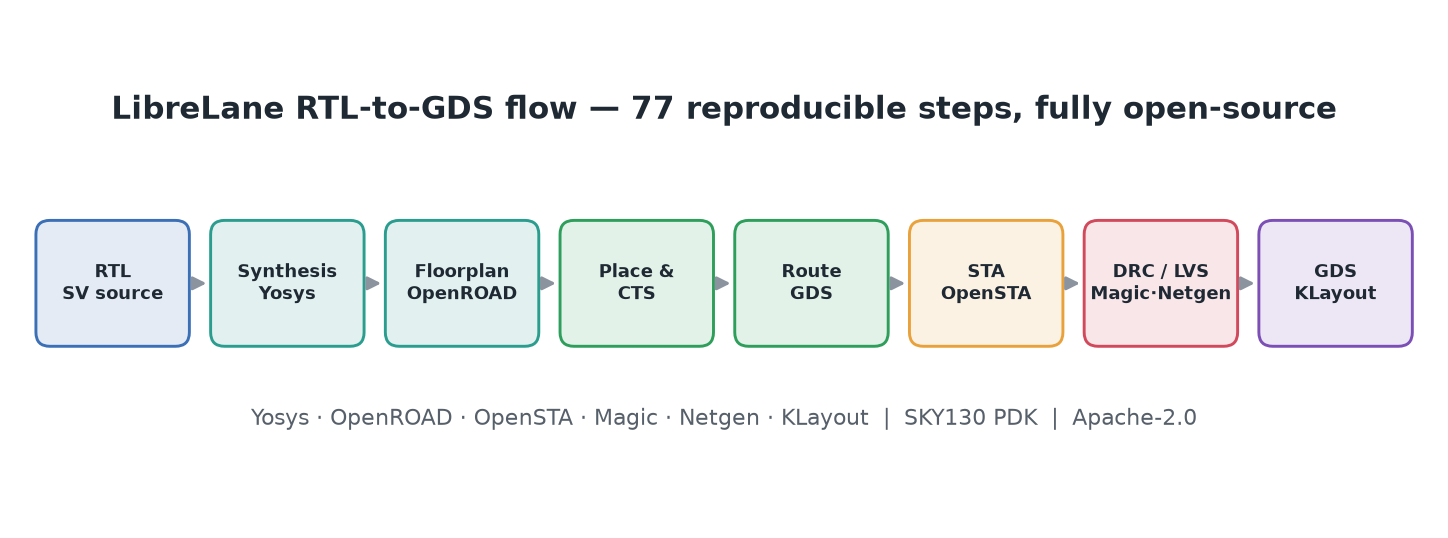

In [3]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_flow.png"), width=1000))

*Figure 1: The LibreLane RTL-to-GDS flow used for every variant. One script drives six open-source engines (Yosys, OpenROAD, OpenSTA, Magic, Netgen, and KLayout), and DRC, LVS, and antenna checks are part of the flow rather than external steps.*

### 7.2 Clocking strategy

U1, U2, and U4 close timing at a 100 ns period (10 MHz) with non-negative setup slack. U16 places 16 rounds in one cycle; its pre-CTS critical path was 132 ns, and OpenROAD's repair loop did not converge on a 100 ns period within the compute budget. U16 is therefore implemented at 300 ns, and every result involving U16 uses that clock. The relaxed clock is the physical reason the measured throughput falls at high unroll (Section 9.6).

### 7.3 Sign-off status

All four hardened variants pass DRC with zero errors, LVS clean, and zero antenna violations at the selected operating corner. Per-corner worst setup slack and estimated Fmax are reported in Section 9, and the complete corner reports are retained with the run artifacts.

U8 (`UNROLL = 8` at 100 ns) reached global routing but did not complete it because OpenROAD reported congestion (`GRT-0116`). Its measured cycle count is included in the design set; no hardened PPA is claimed for it.

## 8. Throughput and energy model

The derived quantities are defined as follows.

- Cycles per 512-bit block: `64 / UNROLL` in the ideal model, measured in RTL simulation. The measured values are 67, 35, 19, 18, and 18 for U1–U16.
- Time per block: `t_blk = cycles_per_block × clock_period`.
- Throughput: `1 / t_blk`, in blocks per second, which equals hashes per second for a single core.
- Energy per hash: `E = P_total × t_blk`.

`P_total` is the vectorless STA power reported by OpenROAD at the operating corner, summed over internal, switching, and leakage power of the standard-cell network. This is a first-order estimate. It does not include I/O pad power and uses default activity factors rather than activity traced from simulation. The resulting energy numbers are therefore suitable for relative comparison across variants, which is what the Pareto analysis requires, and are not absolute silicon measurements.

Energy per hash is the product of power and the time one hash takes. Because U1–U4 share the same 100 ns clock, their throughput gain comes almost entirely from evaluating more rounds per cycle, until the input interface becomes the bottleneck.

## 9. Results

This section recomputes the Pareto table from the committed CSV files and presents the measured results. Sections 9.1–9.4 execute the analysis, and Sections 9.5–9.9 present the figures and the design decision. All figures are embedded in the notebook, so the results are visible without execution.

The analysis uses only `pandas` and `matplotlib` and the committed `data/` directory. The metrics directory is located automatically, whether the notebook runs from the submission package (`data/`) or from the development repository (`results/`).

### 9.1 Load the measured metrics

The cell below loads `metrics.csv`, which contains one row per completed LibreLane run, and displays the columns used in the analysis.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

def find_data():
    """Locate the metrics dir: data/ (submission) or results/ (dev repo).
    Walks the CWD and all parents so the notebook works from any subdirectory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for name in ('data', 'results'):
            d = base / name
            if (d / 'metrics.csv').exists():
                return d
    # Shallow scan of the working directory (helps Colab where the repo is a child).
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for name in ('data', 'results'):
                d = child / name
                if (d / 'metrics.csv').exists():
                    return d
    raise FileNotFoundError('metrics.csv not found in any data/ or results/ directory')

DATA = find_data()
print('Data directory :', DATA.resolve())

dfm = pd.read_csv(DATA / 'metrics.csv')
print('Raw runs       :', len(dfm))
print('Variants       :', sorted(dfm['unroll'].astype(int).unique().tolist()))

show = ['unroll', 'run', 'clock_period_ns', 'area_stdcell_um2',
        'cells_stdcell', 'power_W', 'setup_ws_worst_ns', 'drc_errors']
dfm[show]

Data directory : /mnt/c/Users/USER/Downloads/learning_verilog_and_sv/overagain/hash_pareto/results
Raw runs       : 7
Variants       : [1, 2, 4, 16]


,unroll,run,clock_period_ns,area_stdcell_um2,cells_stdcell,power_W,setup_ws_worst_ns,drc_errors
0,1,grid100,100.0,176750,18423,0.002529,58.8880,0
1,1,hard20,20.0,176977,18441,0.012640,-1.7438,0
2,16,grid300,300.0,524671,59891,0.000916,23.9840,0
3,2,grid100,100.0,197497,20956,0.002566,55.2761,0
4,2,hard35,35.0,196938,20888,0.007275,-2.8628,0
5,4,grid100,100.0,243908,26522,0.002610,24.9893,0
6,4,hard70,70.0,243531,26433,0.003733,-6.2672,0


### 9.2 Recompute the Pareto table and cross-check

The table is rebuilt from `metrics.csv` and `cycles.csv`. For each variant the cell selects one representative run, preferring a timing-closed run and otherwise the tightest clock. The final line reports the maximum energy deviation from the committed `pareto.csv`, which is 0.000% for the measured set.

In [5]:
# Step 1: measured cycles/block (RTL simulation, not the closed-form 64/U).
def load_cycles():
    for base in [DATA, DATA.parent / 'data', DATA.parent / 'results']:
        f = base / 'cycles.csv'
        if f.exists():
            return pd.read_csv(f)
    return pd.DataFrame(columns=['unroll', 'cycles_per_block'])

cdf = load_cycles()

# Step 2: pick ONE representative run per variant. Prefer timing-closed
# (setup_ws_worst_ns >= 0); otherwise the tightest clock, flagged as open.
cand = []
for u, g in dfm.groupby('unroll'):
    closed = g[g['setup_ws_worst_ns'].astype(float) >= 0]
    pool = closed if len(closed) else g
    idx = pool['clock_period_ns'].astype(float).idxmin()
    pick = pool.loc[[idx]].copy()
    pick['timing_closed'] = len(closed) > 0
    cand.append(pick)
dfm_best = (pd.concat(cand, ignore_index=True)
              .sort_values('unroll').reset_index(drop=True)) if cand else pd.DataFrame()

derived = []
for _, r in dfm_best.iterrows():
    u = int(r['unroll'])
    mrow = cdf[cdf['unroll'] == u]
    cycles = float(mrow['cycles_per_block'].iloc[0]) if len(mrow) else 64.0 / u
    t_blk = cycles * float(r['clock_period_ns']) * 1e-9          # seconds per block
    derived.append({
        'unroll': u,
        'run': r['run'],
        'clock_ns': r['clock_period_ns'],
        'timing_closed': bool(r['timing_closed']),
        'area_um2': r['area_stdcell_um2'],
        'cells': int(r['cells_stdcell']),
        'power_mW': r['power_W'] * 1e3,
        'cycles_per_block': cycles,
        'throughput_Mhash_s': (1 / t_blk) / 1e6,
        'energy_nJ': (r['power_W'] * t_blk) * 1e9,
    })
dfp = pd.DataFrame(derived).sort_values('unroll').reset_index(drop=True)

# Step 3: cross-check against the committed pareto.csv.
try:
    ref = pd.read_csv(DATA / 'pareto.csv')
    chk = dfp.merge(ref, on='unroll', suffixes=('_live', '_ref'))
    dE = (100 * (chk['energy_nJ'] - chk['energy_per_hash_nJ']).abs()
          / chk['energy_per_hash_nJ']).max()
    print('max energy deviation vs committed pareto.csv: %.3f %%' % dE)
except Exception as e:
    print('cross-check skipped:', e)

dfp.round(3)

max energy deviation vs committed pareto.csv: 0.000 %


,unroll,run,clock_ns,timing_closed,area_um2,cells,power_mW,cycles_per_block,throughput_Mhash_s,energy_nJ
0,1,grid100,100.0,True,176750,18423,2.529,67.0,0.149,16.943
1,2,grid100,100.0,True,197497,20956,2.566,35.0,0.286,8.980
2,4,grid100,100.0,True,243908,26522,2.610,19.0,0.526,4.959
3,16,grid300,300.0,True,524671,59891,0.916,18.0,0.185,4.947


### 9.3 Live Pareto curves

The two panels below are generated at run time from the recomputed table. They reproduce the committed figures in Section 9.5 from first principles.

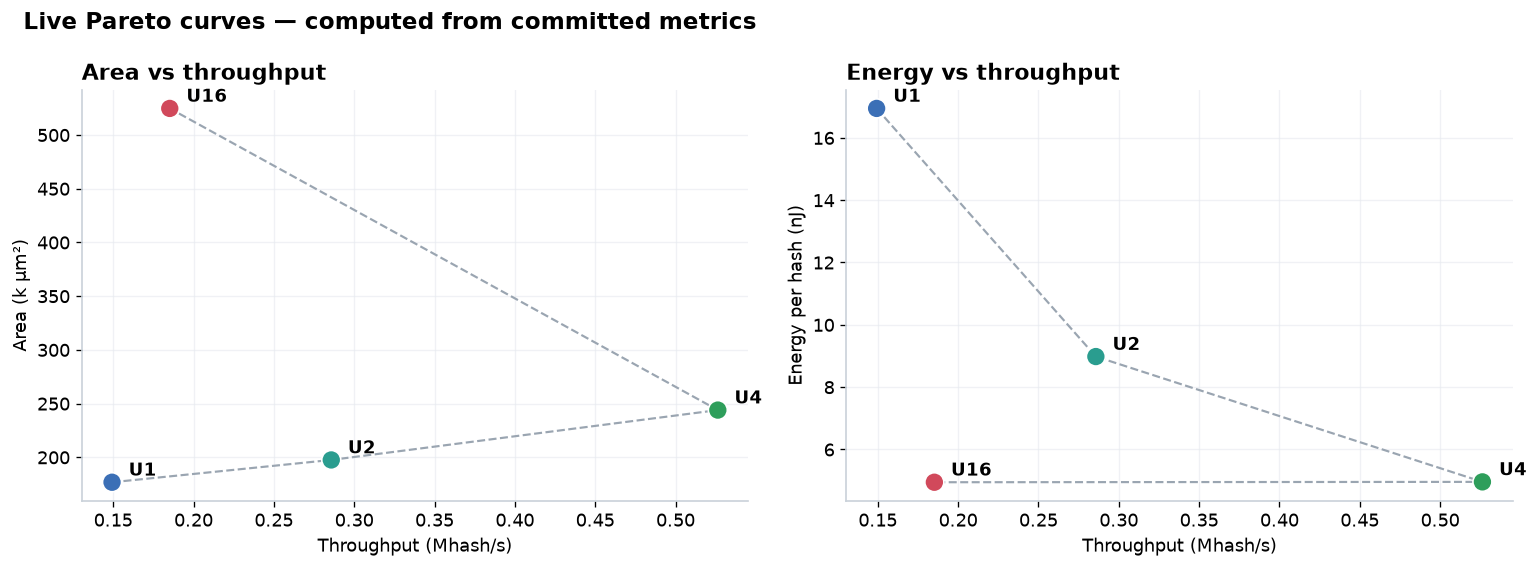

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.edgecolor': '#c9d1d9', 'axes.linewidth': 1.0,
    'axes.grid': True, 'grid.color': '#e6e9ef', 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

CLR = {1: '#3B6FB6', 2: '#2A9D8F', 4: '#2E9E5B', 16: '#D1495B'}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.plot(dfp.throughput_Mhash_s, dfp.area_um2 / 1e3, '--', color='#9aa5b1', lw=1.3)
ax.scatter(dfp.throughput_Mhash_s, dfp.area_um2 / 1e3, s=130,
           c=[CLR.get(int(u), '#888') for u in dfp.unroll], edgecolor='white', zorder=3)
for _, r in dfp.iterrows():
    ax.annotate(f'U{int(r.unroll)}', (r.throughput_Mhash_s, r.area_um2 / 1e3),
                textcoords='offset points', xytext=(10, 4), fontweight='bold')
ax.set_xlabel('Throughput (Mhash/s)')
ax.set_ylabel('Area (k µm²)')
ax.set_title('Area vs throughput', loc='left')
ax.grid(alpha=0.6)

ax = axes[1]
ax.plot(dfp.throughput_Mhash_s, dfp.energy_nJ, '--', color='#9aa5b1', lw=1.3)
ax.scatter(dfp.throughput_Mhash_s, dfp.energy_nJ, s=130,
           c=[CLR.get(int(u), '#888') for u in dfp.unroll], edgecolor='white', zorder=3)
for _, r in dfp.iterrows():
    ax.annotate(f'U{int(r.unroll)}', (r.throughput_Mhash_s, r.energy_nJ),
                textcoords='offset points', xytext=(10, 4), fontweight='bold')
ax.set_xlabel('Throughput (Mhash/s)')
ax.set_ylabel('Energy per hash (nJ)')
ax.set_title('Energy vs throughput', loc='left')
ax.grid(alpha=0.6)

fig.suptitle('Live Pareto curves — computed from committed metrics',
             x=0.02, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

### 9.4 Live PPA bars

The four panels summarize area, throughput, energy per hash, and power for the recomputed design points.

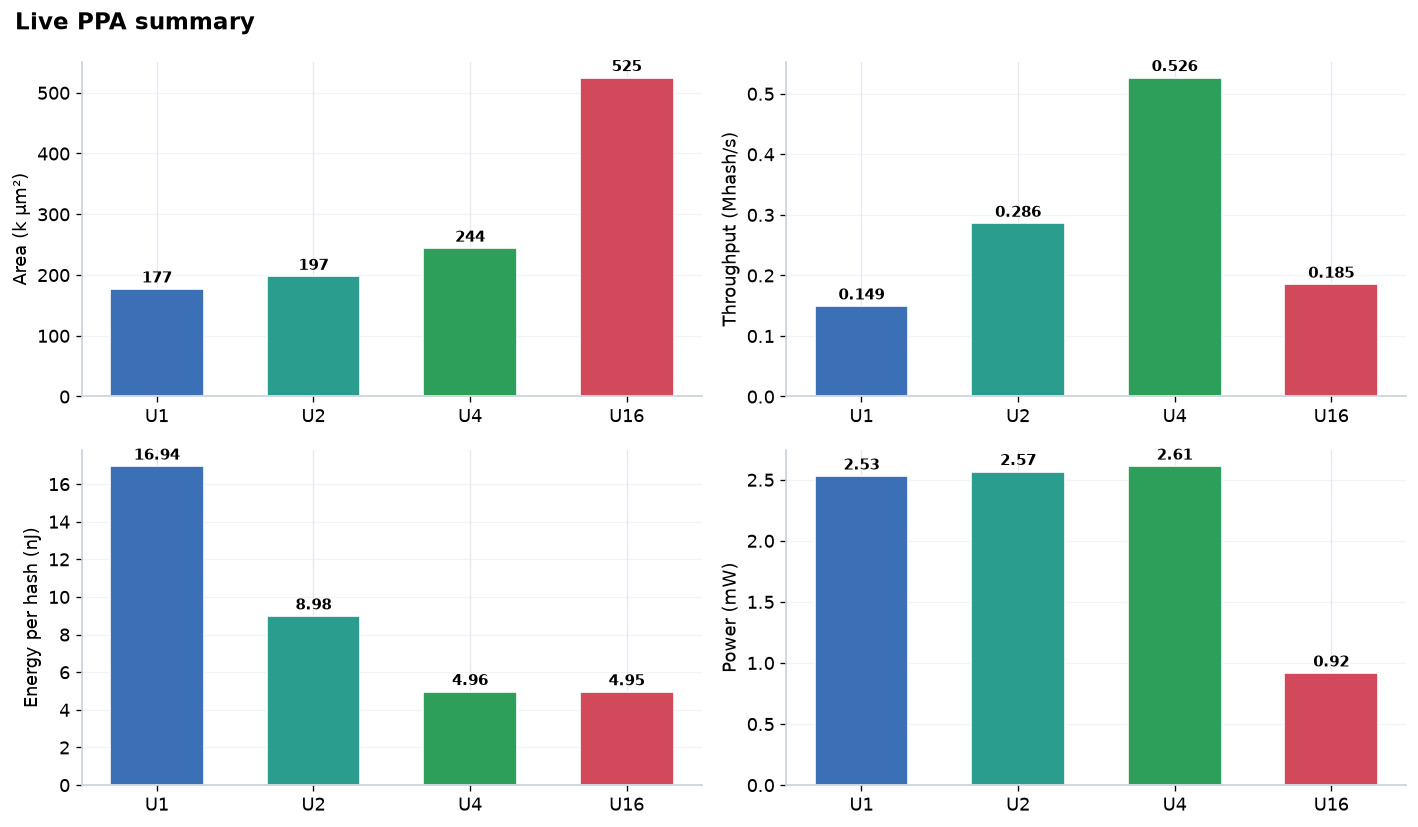

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
labels = [f'U{int(u)}' for u in dfp.unroll]
cols = [CLR.get(int(u), '#888') for u in dfp.unroll]
panels = [
    ('Area (k µm²)', dfp.area_um2 / 1e3, '{:,.0f}'),
    ('Throughput (Mhash/s)', dfp.throughput_Mhash_s, '{:.3f}'),
    ('Energy per hash (nJ)', dfp.energy_nJ, '{:.2f}'),
    ('Power (mW)', dfp.power_mW, '{:.2f}'),
]
for ax, (lab, vals, fmt) in zip(axes.ravel(), panels):
    bars = ax.bar(labels, vals, color=cols, width=0.6, edgecolor='white')
    for b, v in zip(bars, vals):
        ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v),
                    textcoords='offset points', xytext=(0, 4), ha='center',
                    fontsize=9, fontweight='bold')
    ax.set_ylabel(lab)
    ax.grid(alpha=0.5, axis='y')
fig.suptitle('Live PPA summary', x=0.02, ha='left', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

### 9.5 Pareto and PPA figures

The two Pareto plots form a pair: the first shows the area cost of throughput, the second shows the energy returned for that cost. Each point is labeled `U<unroll>`; the dashed line is a visual guide only, since no intermediate designs were measured. The bar chart summarizes the four figures of merit for the four hardened variants.

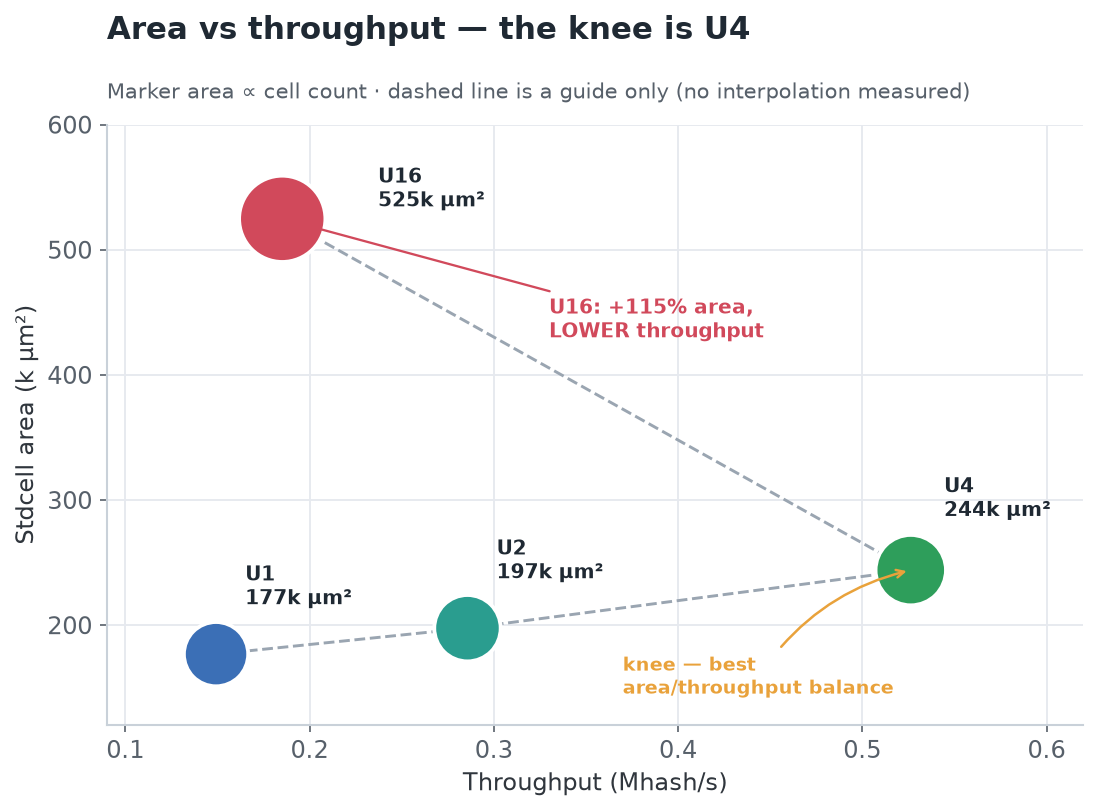

In [8]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_pareto_area.png"), width=900))

*Figure 2: Area versus throughput. Throughput increases almost linearly from U1 to U4 while area grows by 38%. Beyond U4 the curve turns over: U16 requires 115% more area than U4 but delivers lower throughput (0.185 versus 0.526 Mhash/s) because its clock is relaxed to 300 ns. The knee of the curve is U4.*

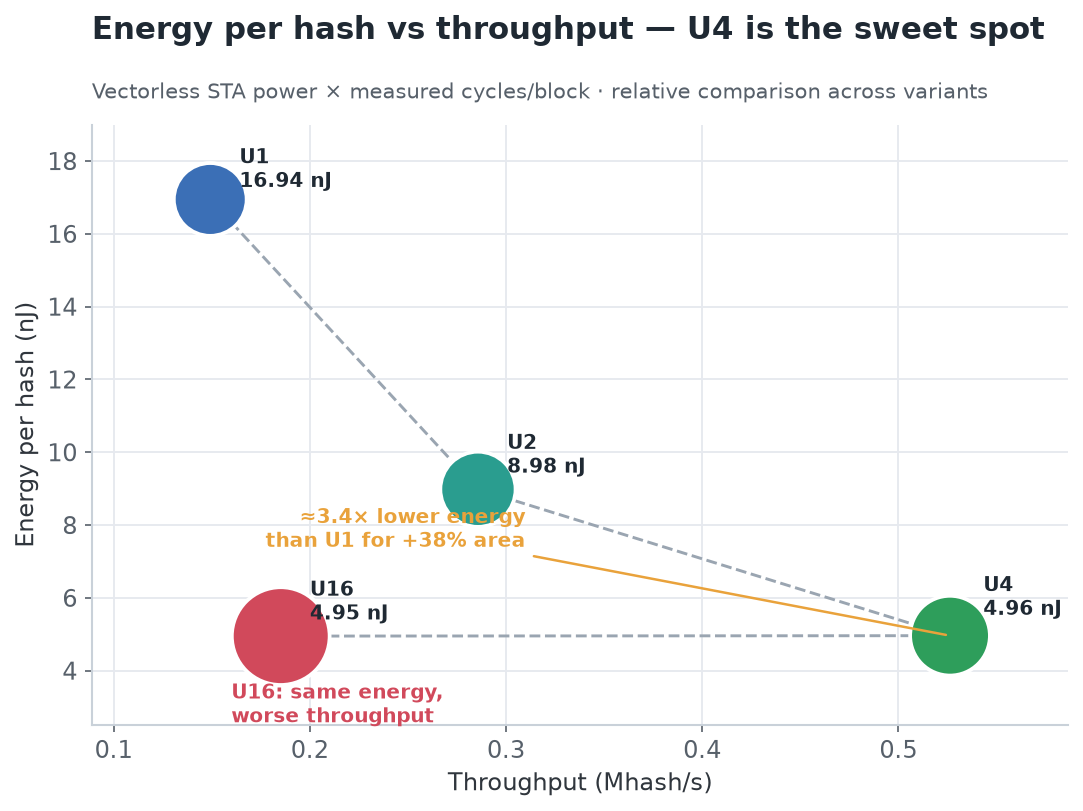

In [9]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_pareto_energy.png"), width=900))

*Figure 3: Energy per hash versus throughput. Energy falls steeply from U1 to U4 (16.94 to 4.96 nJ per hash) while throughput more than triples (0.149 to 0.526 Mhash/s). Past U4 the curve collapses: U16 requires 115% more area for lower throughput at essentially the same energy (4.95 nJ per hash). U4 is the energy-optimal point per unit area.*

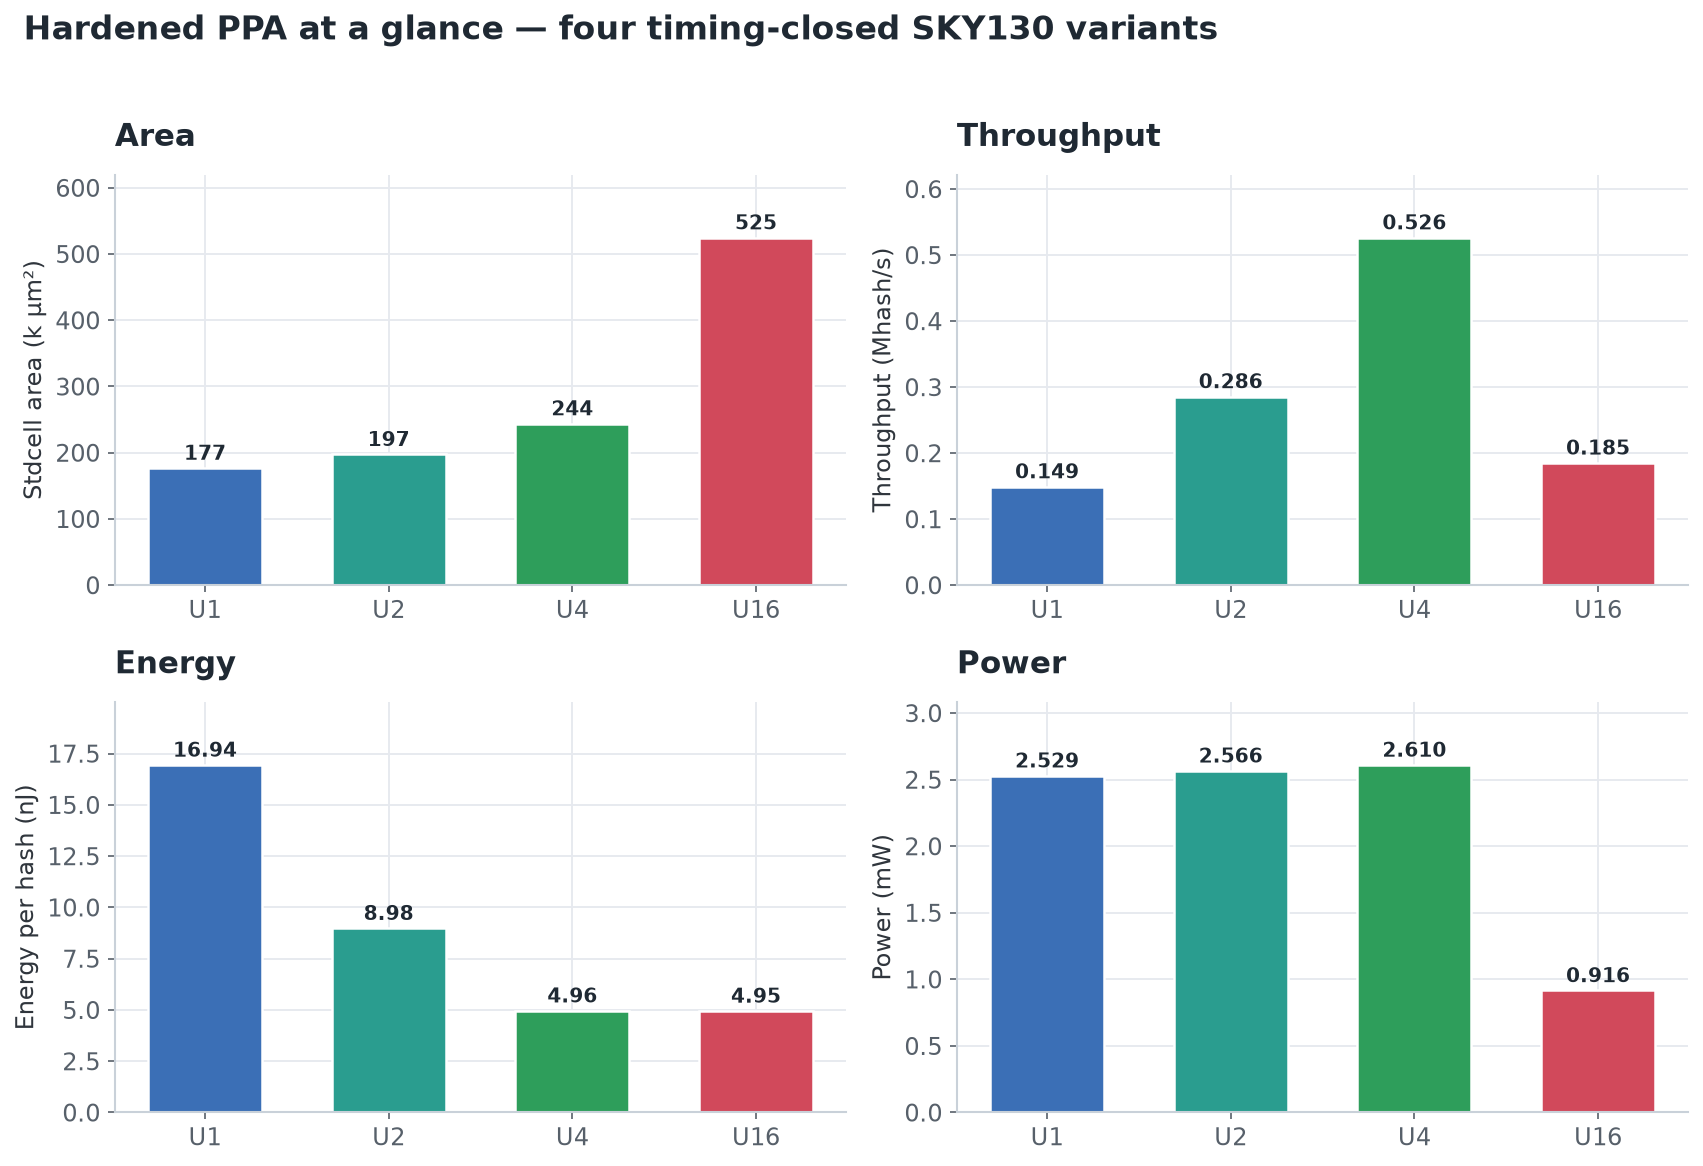

In [10]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_bars_metrics.png"), width=1000))

*Figure 4: Hardened PPA for the four timing-closed SKY130 variants. Power is nearly flat across U1–U4 at a shared 100 ns clock, indicating that the clock tree rather than the round logic dominates the power of these designs.*

### 9.6 Cycles and clocking

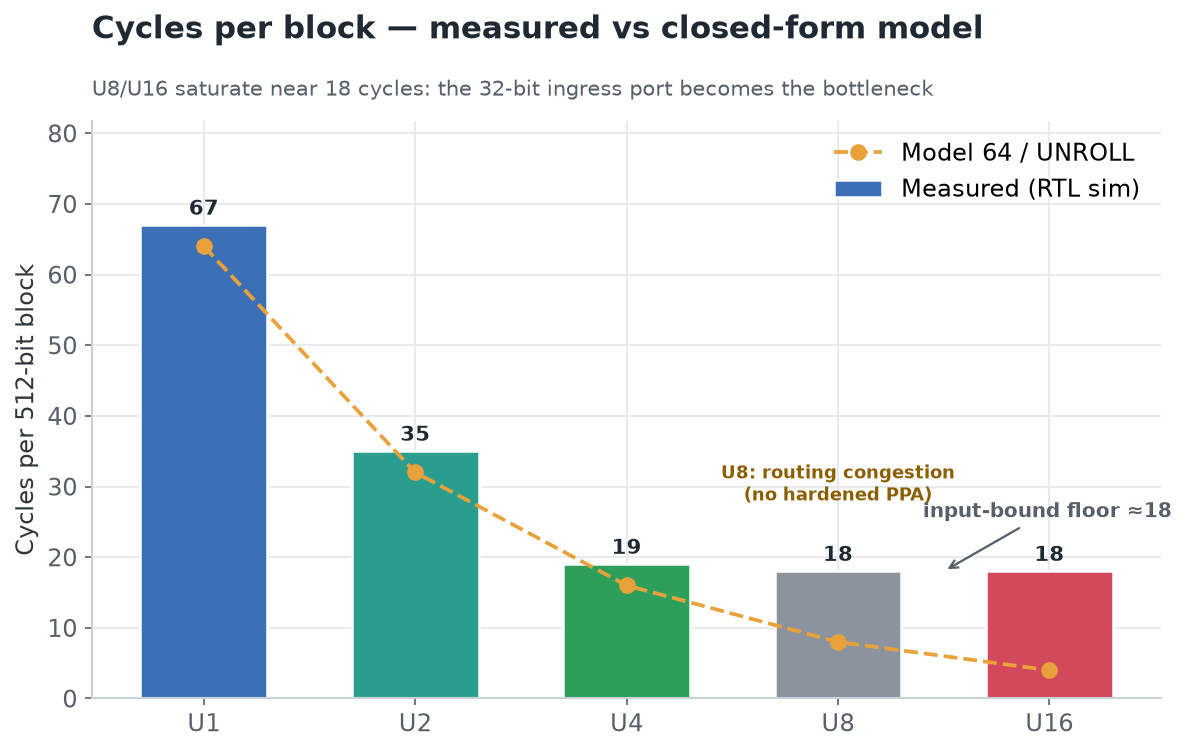

In [11]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_cycles.png"), width=950))

*Figure 5: Cycles per block, measured versus modeled. The closed-form 64/UNROLL model (dashed) diverges from measurement (bars) once the core saturates at approximately 18 cycles per block. The 32-bit ingress port becomes the bottleneck, which is why U8 and U16 do not improve throughput despite additional round logic.*

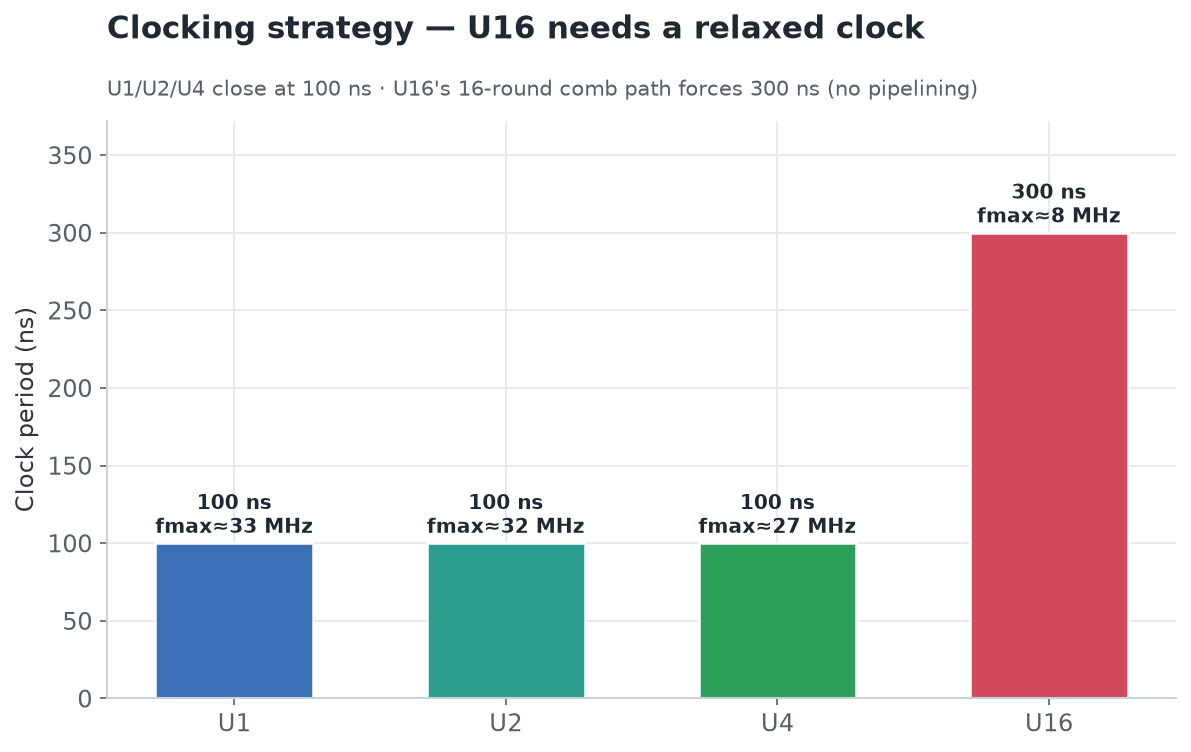

In [12]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_fmax.png"), width=950))

*Figure 6: Clocking strategy. U1, U2, and U4 close at 100 ns; U16's 16-round combinational path requires a 300 ns clock. This is the physical cause of the throughput roll-over at high unroll.*

### 9.7 Power

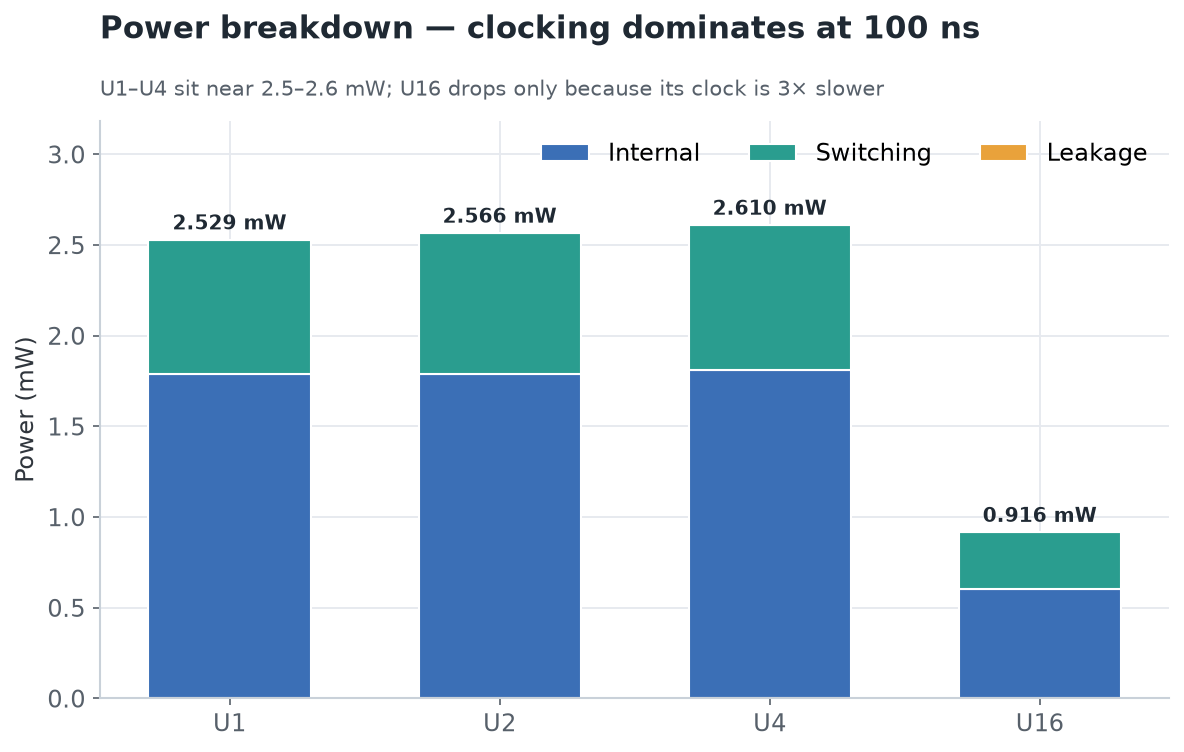

In [13]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_power.png"), width=950))

*Figure 7: Power breakdown from vectorless STA (internal, switching, and leakage). U1–U4 sit near 2.5–2.6 mW despite very different cell counts; U16 is lower only because its clock is three times slower. Energy per hash (Figure 3) is the fair cross-variant metric.*

### 9.8 Layout evidence

The four hardened variants are rendered from their final GDS with KLayout (`tools/render_layout.sh`). Standard-cell rows, the clock tree, and the I/O pads are visible, and the die grows with unroll as the round logic and clock tree expand. Each image is a completed GDS, not a schematic.

| Variant | Die area (µm²) | Standard-cell area (µm²) | Utilization | DRC errors |
|:--|--:|--:|--:|--:|
| U1 | 279,162 | 176,750 | 67.5% | 0 |
| U2 | 320,412 | 197,497 | 65.4% | 0 |
| U4 | 403,704 | 243,908 | 63.8% | 0 |
| U16 | 887,825 | 524,671 | 61.3% | 0 |

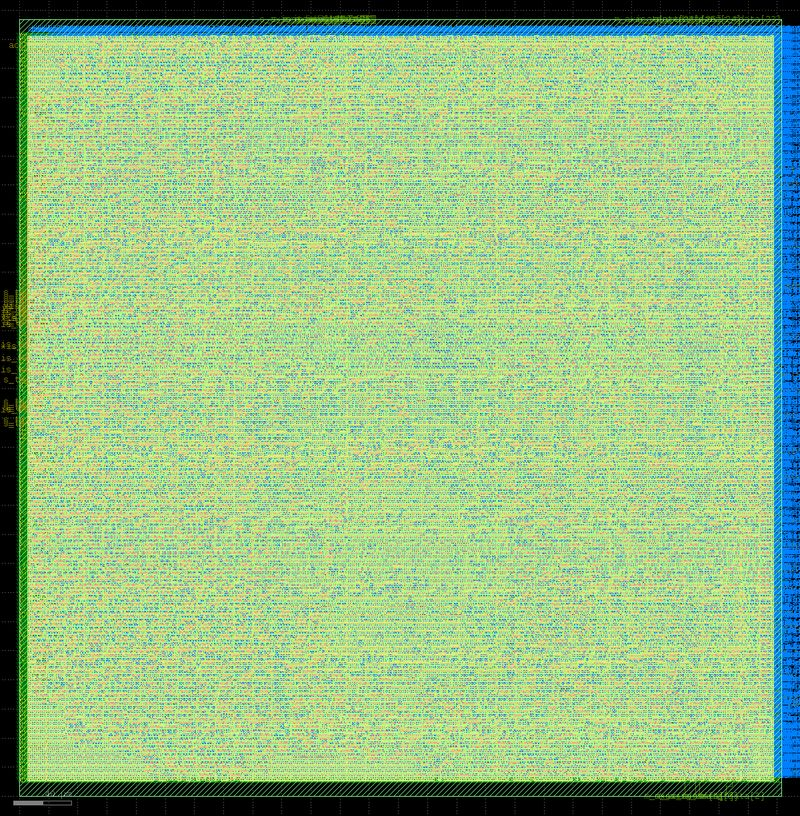

In [14]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "layout_u1.jpg"), width=720))

*Figure 8: U1 layout (UNROLL = 1, 100 ns). Smallest core and the baseline for area and energy.*

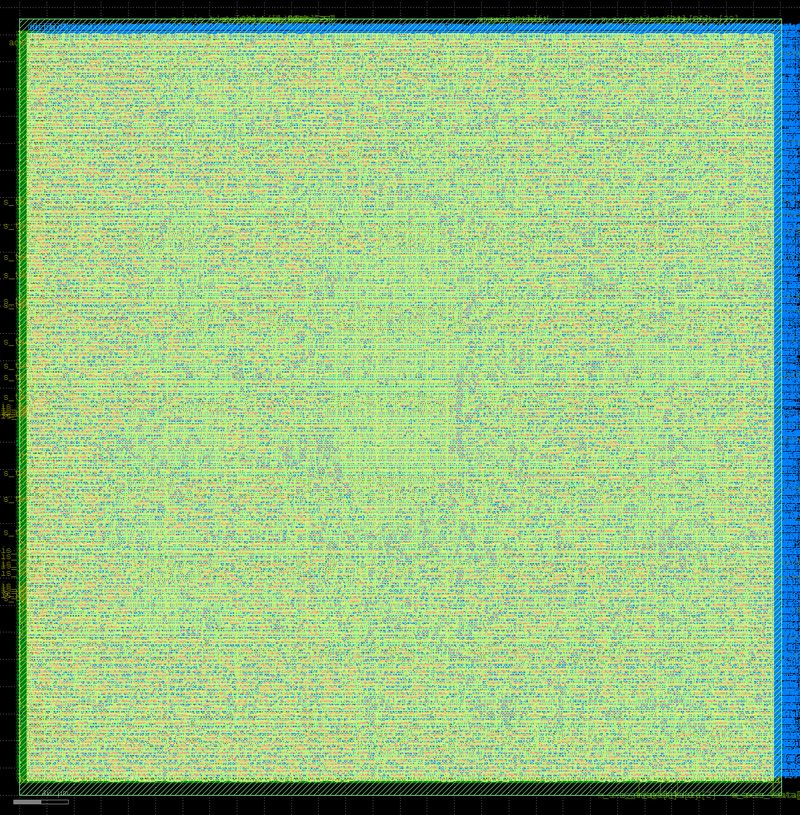

In [15]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "layout_u2.jpg"), width=720))

*Figure 9: U2 layout (UNROLL = 2, 100 ns). Area is 12% above U1, cycles are nearly halved (35), and energy is approximately 47% lower.*

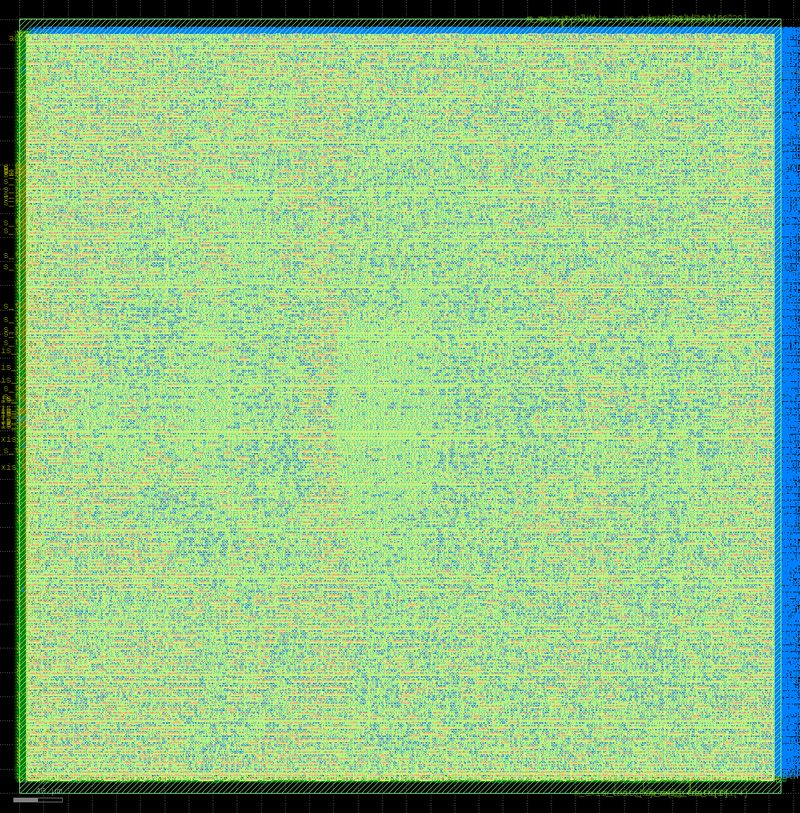

In [16]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "layout_u4.jpg"), width=720))

*Figure 10: U4 layout (UNROLL = 4, 100 ns). The knee: 38% more area than U1, approximately 3.4× lower energy per hash, and 3.5× higher throughput.*

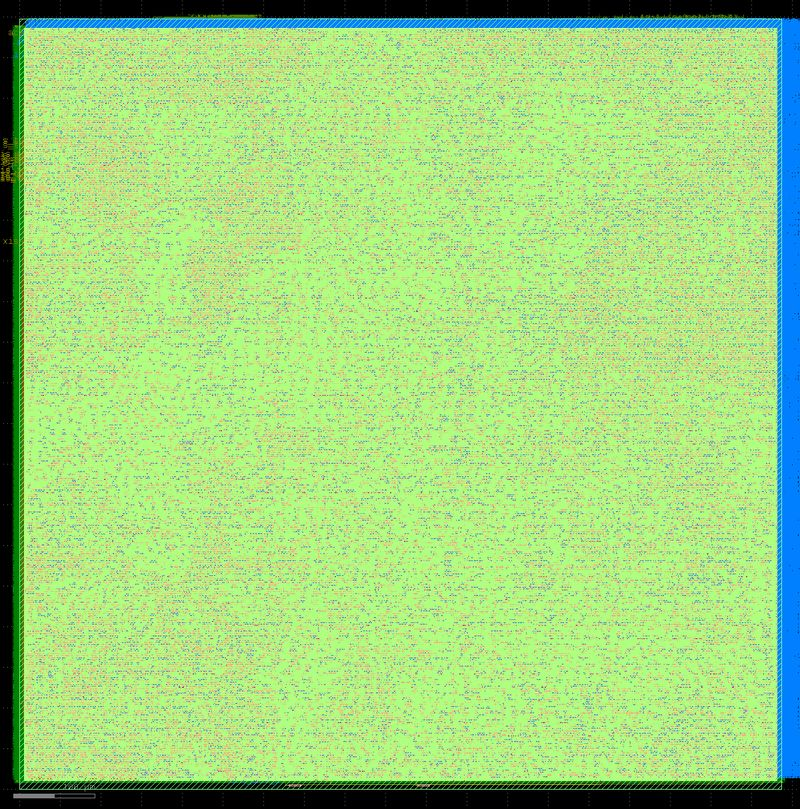

In [17]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "layout_u16.jpg"), width=720))

*Figure 11: U16 layout (UNROLL = 16, 300 ns). The largest die; the three-times-slower clock cancels the additional parallelism, and the point is dominated by U4.*

### 9.9 Summary and observations

| UNROLL | Area (µm²) | Throughput (Mhash/s) | Energy per hash (nJ) | Power (mW) | Clock | Timing closed |
|-------:|-----------:|---------------------:|---------------------:|-----------:|------:|:-------------:|
| 1 | 176,750 | 0.149 | 16.94 | 2.53 | 100 ns | Yes |
| 2 | 197,497 | 0.286 | 8.98 | 2.57 | 100 ns | Yes |
| 4 | 243,908 | **0.526** | **4.96** | 2.61 | 100 ns | Yes |
| 16 | 524,671 | 0.185 | 4.95 | 0.92 | 300 ns | Yes |

Three observations follow from the table.

1. **U1 to U4 is the useful range.** Area grows by 38% while energy per hash falls by approximately 3.4× (16.94 to 4.96 nJ) and throughput increases almost linearly (0.149 to 0.526 Mhash/s). Most of the benefit is obtained for a modest area cost.
2. **U16 does not pay.** It requires 115% more area than U4, throughput falls (0.526 to 0.185 Mhash/s) because the 16-round path forces a 300 ns clock, and energy per hash is essentially unchanged (4.95 versus 4.96 nJ). U16 is dominated by U4 on this architecture.
3. **Power is dominated by clocking.** U1, U2, and U4 all dissipate approximately 2.5–2.6 mW at the same 100 ns clock despite very different cell counts; clock-tree and register activity dominate the combinational differences.

The energy values use the vectorless STA power estimate, `P_total × cycles_per_block / f_clk`, with measured cycles per block rather than the closed-form 64/UNROLL. The figures are therefore used to compare variants, not as absolute silicon measurements.

The data therefore favor four rounds per cycle. Unrolling beyond that point is not justified here because the input interface, not the round logic, becomes the throughput limit.

### 9.10 Worked example: U1 to U4

| Step | U1 | U4 | Change |
|:--|--:|--:|--:|
| Cycles per block | 67 | 19 | -72% |
| Clock period | 100 ns | 100 ns | — |
| Time per block | 6.70 µs | 1.90 µs | -72% |
| Throughput | 0.149 Mhash/s | 0.526 Mhash/s | 3.5× |
| Power | 2.53 mW | 2.61 mW | +3% |
| Energy per hash | 16.94 nJ | 4.96 nJ | -71% |
| Area | 176,750 µm² | 243,908 µm² | +38% |

The table summarizes the case for U4: 72% less time per hash for 38% more area at essentially unchanged power.

## 10. Discussion

### 10.1 Interpretation

The measured curve is consistent with a simple model. Below four rounds per cycle, the round logic sets the block latency, so throughput scales with unroll and energy per hash falls. Above four rounds, the 32-bit ingress port cannot supply a 512-bit block faster than approximately 18 cycles, so additional round logic adds area and critical-path depth without reducing the time per block. U16 also requires a 300 ns clock because its 16-round path was 132 ns before clock-tree synthesis. The combination of a stalled interface and a relaxed clock makes U16 strictly worse than U4.

The flat power across U1–U4 has the same origin. At 100 ns and this cell count, clock-tree and register power dominate, so increasing the combinational round logic by a factor of four changes total power by only a few percent. Energy per hash, which multiplies power by block time, is the quantity that separates the designs.

### 10.2 Design guidance

For a streaming SHA-256 core with a 32-bit ingress port implemented on SKY130, the measurements support three recommendations.

- **Energy-first designs:** use UNROLL = 4. It provides the lowest energy per hash at the highest throughput of the measured set, for 38% more area than the iterative core.
- **Area-constrained designs:** use UNROLL = 1 or 2. U1 minimizes area; U2 recovers nearly half of the energy per hash for 12% more area.
- **High-unroll designs:** use UNROLL = 16 only with a wider ingress interface or a pipelined round path. With the current 32-bit interface, the additional round logic does not increase throughput and more than doubles the area relative to U4.

These recommendations follow from the measured design set and are not extrapolated beyond it.

## 11. Reproducibility

### 11.1 Three-tier model

Every number in this notebook has a recorded origin: a run tag, a LibreLane version, and a date stored with the metric. The notebook supports three depths of reproduction.

| Tier | Requirements | Time | Result |
|:--|:--|:--|:--|
| Tier 0, read | `pandas`, `matplotlib` | seconds | All tables and figures, recomputed from committed CSVs and images |
| Tier 1, verify | `cocotb`, Icarus Verilog or Verilator | approximately 2 minutes | Functional matrix and measured cycles per block from RTL |
| Tier 2, harden | LibreLane and SKY130 | 30–45 minutes per variant | Full RTL-to-GDS run, fresh metrics, fresh layouts |

Figure 12 summarizes the tiers and the artifacts associated with each.

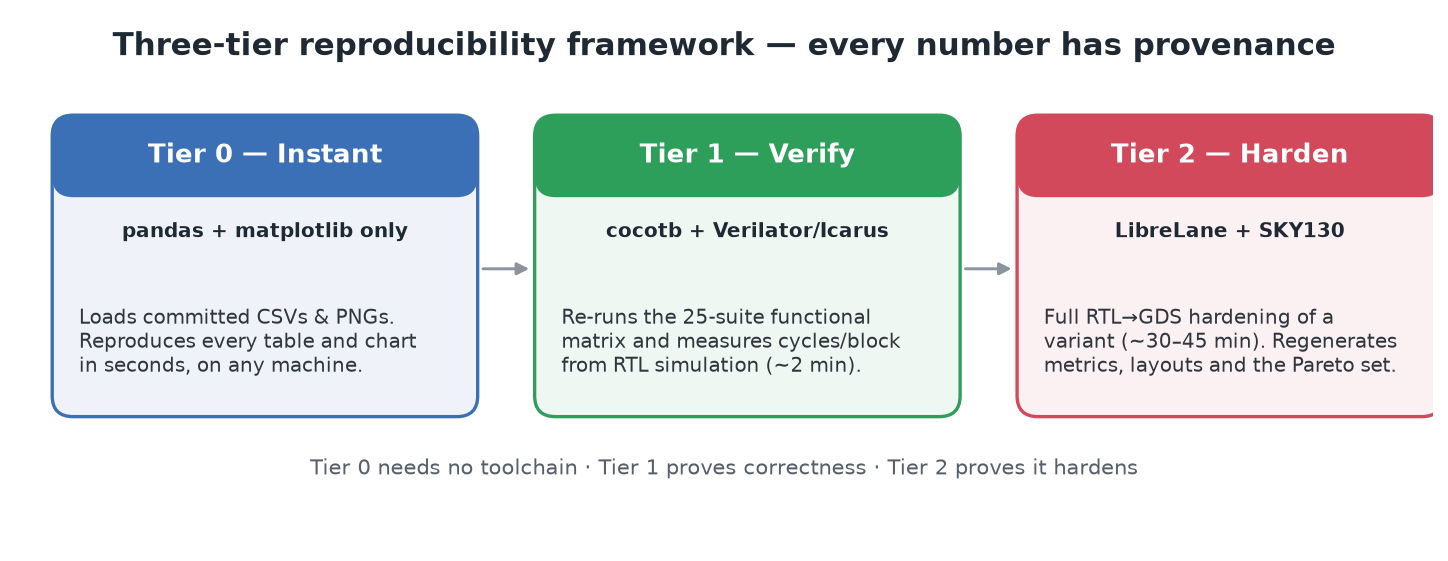

In [18]:
from IPython.display import Image, display
from pathlib import Path

def _figdir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for nm in ('data', 'results'):
            d = base / nm / 'figures'
            if d.exists():
                return d
    for child in Path.cwd().glob('*'):
        if child.is_dir():
            for nm in ('data', 'results'):
                d = child / nm / 'figures'
                if d.exists():
                    return d
    return Path('data/figures')

display(Image(filename=str(_figdir() / "fig_tiers.png"), width=1000))

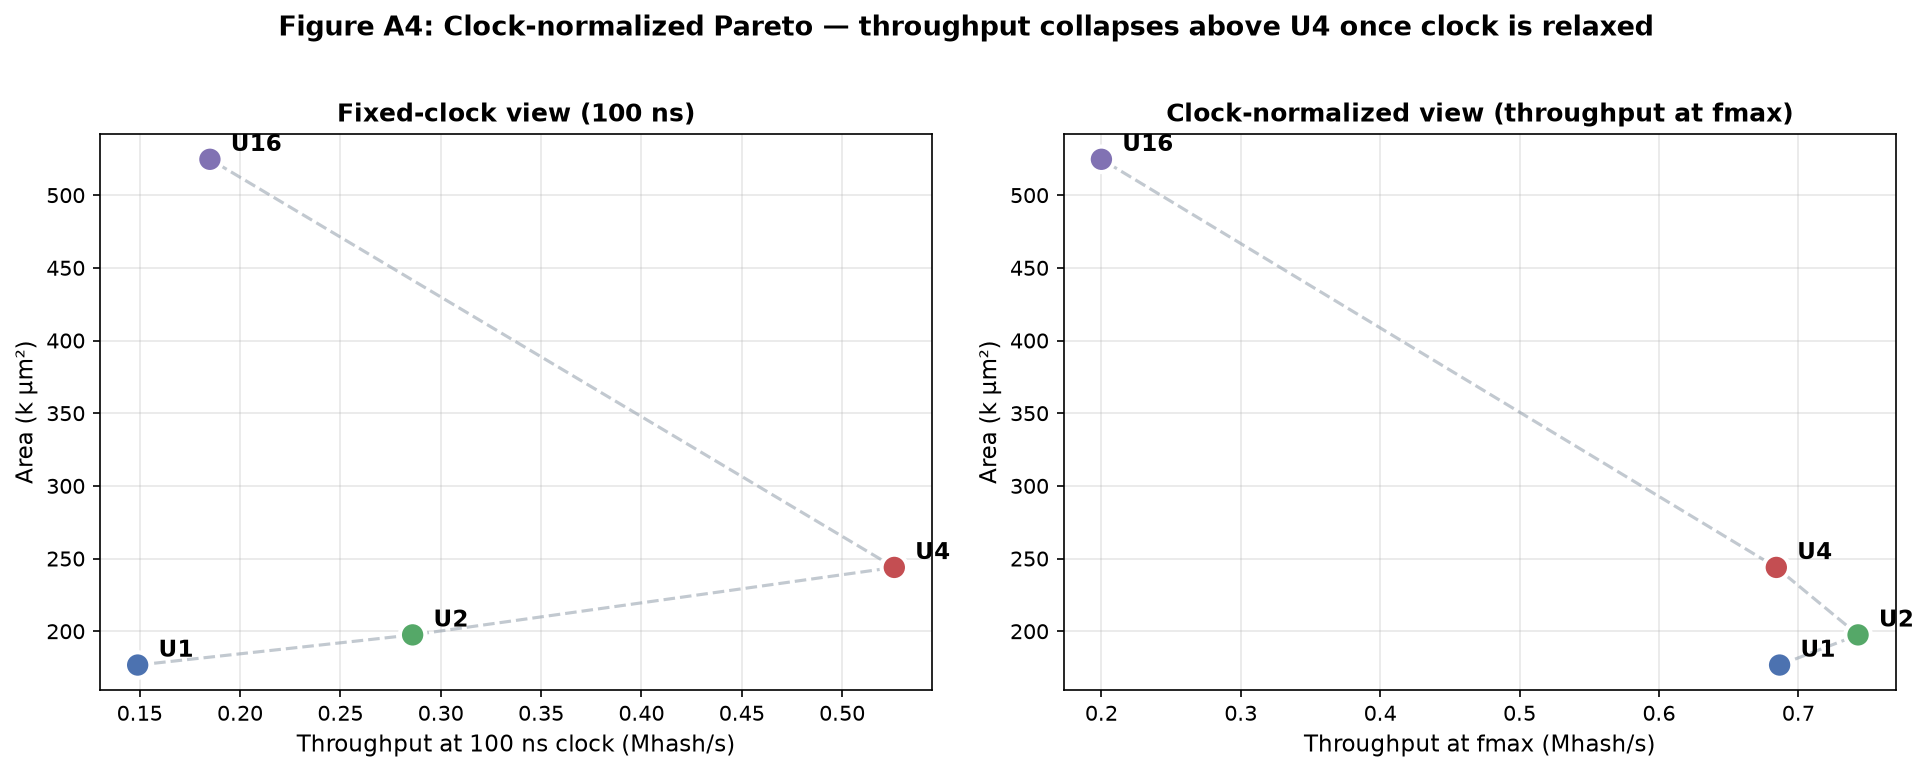

In [ ]:
from IPython.display import Image, display
from base64 import b64decode

a4_img = "..."

if a4_img:
    display(Image(data=b64decode(a4_img), width=900))


*Figure A4: Clock-normalized Pareto. Left: throughput at the fixed 100 ns clock (the published view). Right: throughput at each variant's own fmax. At fmax, throughput is nearly flat across U1–U4 (~0.7 Mhash/s) because the ingress interface saturates at ~18 cycles per block; U16 collapses to ~0.2 Mhash/s due to its 300 ns clock. The apparent 3.5× throughput gain of U4 over U1 is therefore a fixed-clock artifact, not an fmax property.*

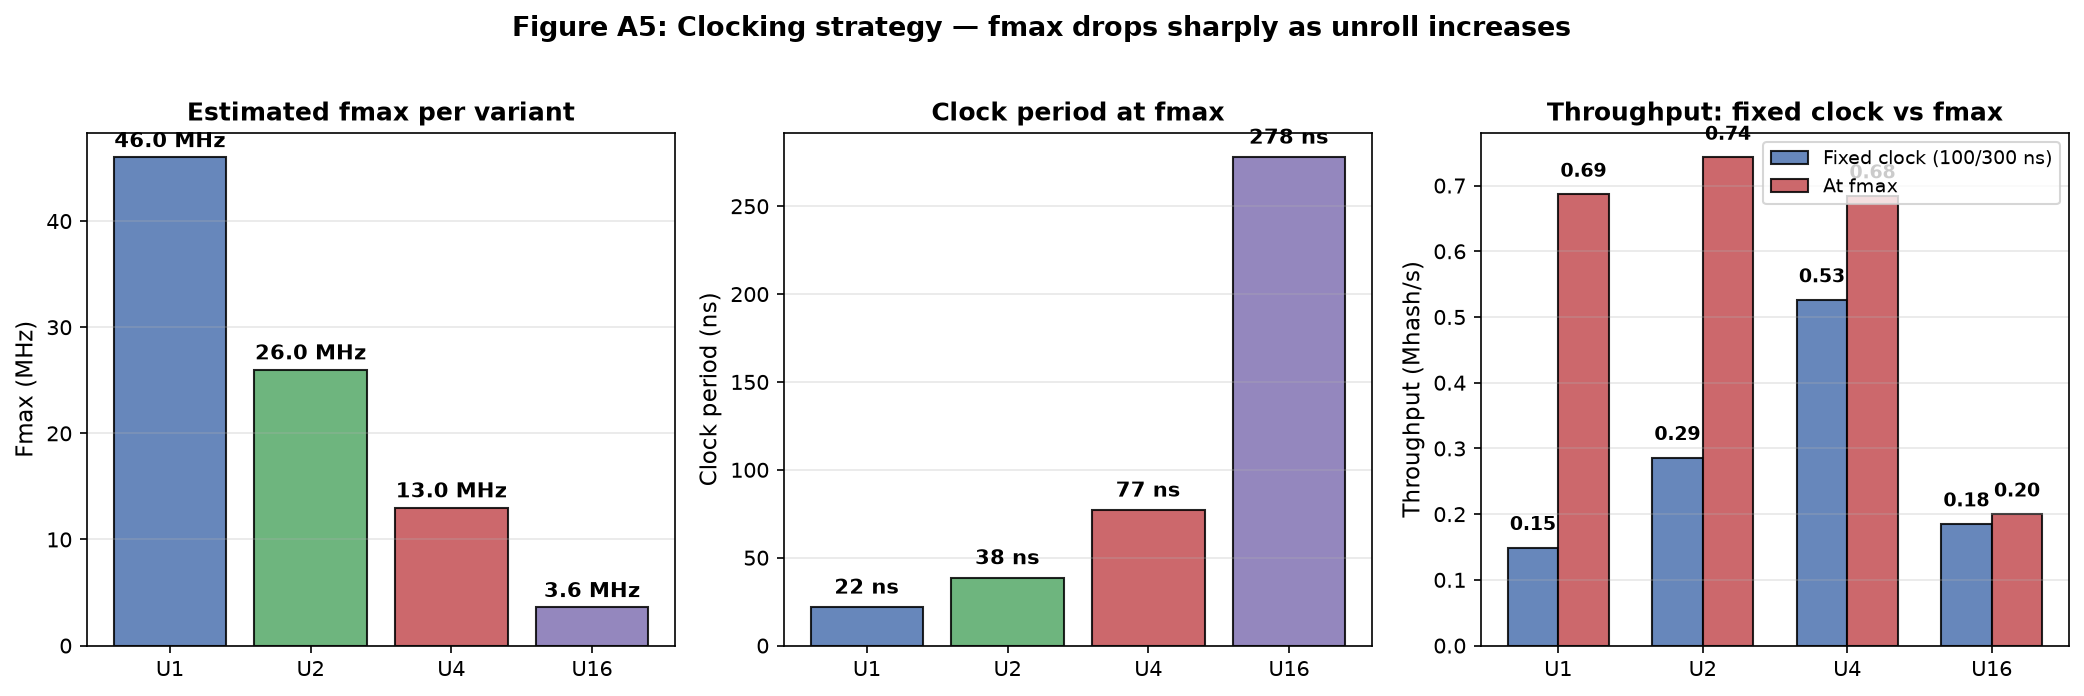

In [ ]:
from IPython.display import Image, display
from base64 import b64decode

a5_img = "..."

if a5_img:
    display(Image(data=b64decode(a5_img), width=900))


*Figure A5: Clocking strategy. Fmax drops sharply with unroll (46 MHz for U1 → 3.6 MHz for U16) because the combinational path grows with the round logic. U16's 16-round path requires a 300 ns clock, which more than cancels its parallelism advantage. Throughput at fmax is essentially flat across U1–U4 and collapses at U16.*

*Figure 12: Three-tier reproducibility model. Tier 0 loads committed CSVs and images, Tier 1 re-runs verification and cycle measurement, and Tier 2 performs full hardening and regenerates the metrics and layouts. The tier from which a number was obtained is recorded with the number.*

### 11.2 Reproducing the full flow

Sections 9.1–9.4 run anywhere with `pandas` and `matplotlib` and use only the committed `data/` files. The full flow requires the toolchain from Section 2 and approximately 4 GB of RAM and 10 GB of disk.

```bash
# 1. Functional verification (~2 min)
for u in 1 2 4 8 16; do
    ~/venv/bin/python verif/cocotb/run.py --sim verilator --unroll $u
done

# 2. Harden one variant (~30-45 min each)
tools/run_variant.sh 2 test_u2
tools/slim_run.sh flow/variants/u2/runs/test_u2

# 3. Harvest metrics and regenerate the figures
~/venv/bin/python tools/collect_metrics.py
~/venv/bin/python tools/make_plots.py

# 4. Optional: render a GDS to PNG
tools/render_layout.sh flow/variants/u2/runs/test_u2/final/gds/sha_top.gds out.png 1200
```

The tables and charts in Section 9 are computed from `data/metrics.csv` and `data/pareto.csv`; no values are entered by hand.

### 11.3 Data provenance and packaging

Each row of `metrics.csv` records `run`, `clock_period_ns`, `area_stdcell_um2`, `cells_stdcell`, `power_W`, `setup_ws_worst_ns`, `drc_errors`, `antenna_violations`, `design_violations`, and per-corner slack and Fmax estimates.

The notebook locates its data automatically: it searches for `data/` (submission layout) or `results/` (development layout) in the current directory and its parents. Large `flow/runs/` artifacts remain local and are excluded from version control; only the committed CSVs and rendered images (under 5 MB in total) are required for the notebook to execute.

The project is licensed under Apache-2.0 (see `LICENSE` and `NOTICE`). The original `nano_hash` core is also Apache-2.0 and is vendored unchanged under `rtl/original/`.

**Citation.** Chimbuchi, B. J., *HashPareto: A Reproducible PPA and Pareto Exploration of an Open-Source SHA-256 Core*, IEEE SSCS Code-a-Chip, ISSCC 2027.

## 12. Conclusion

This submission has presented a measured design-space exploration of a parameterized SHA-256 core on SkyWater SKY130. Five unroll factors were verified bit-exact, four were implemented to GDS with DRC/LVS/antenna sign-off, and their area, power, and measured cycles were combined into a Pareto analysis.

The measurements support three conclusions.

1. Unrolling to four rounds is worthwhile. U4 lowers energy per hash by approximately 3.4× relative to U1 (16.94 to 4.96 nJ) for 38% more area, and raises throughput from 0.149 to 0.526 Mhash/s.
2. Unrolling beyond four rounds does not help on this architecture. U16 requires 115% more area than U4, runs at a 300 ns clock, and delivers lower throughput at essentially the same energy per hash.
3. The limiting factor above four rounds is the 32-bit ingress interface, not the round logic. This is visible in the measured cycles per block, approximately 18 regardless of unroll beyond 4, and in the throughput roll-over.

The workflow is scripted under `tools/`, the RTL and verification harness are included, and every reported number can be recomputed from committed data. The same procedure applies to other unroll factors, other interfaces, and other open PDKs. The RTL, verification harness, flow configuration, committed metrics, and this notebook are included so that the complete result can be reproduced.

**Acknowledgements.** This work used LibreLane, OpenROAD, Yosys, Magic, Netgen, KLayout, Verilator, and cocotb, and the SkyWater SKY130 PDK. Their maintainers and contributors made the study possible.

## 13. References

[1] NIST, *FIPS PUB 180-4: Secure Hash Standard (SHS)*, 2015. <https://nvlpubs.nist.gov/nistpubs/FIPS/NIST.FIPS.180-4.pdf>

[2] `nano_hash`, reference SHA-256 core and testbenches (Apache-2.0), vendored unchanged under `rtl/original/`. <https://github.com/chijindumu/nano_hash>

[3] LibreLane, RTL-to-GDS flow (Apache-2.0), version 3.0.16. <https://github.com/librelane/librelane>

[4] OpenLane 2 (Apache-2.0) <https://github.com/efabless/openlane2>; Yosys (ISC) <https://github.com/YosysHQ/yosys>; OpenROAD and OpenSTA (Apache-2.0) <https://github.com/The-OpenROAD-Project/OpenROAD>; Magic VLSI and Netgen <http://opencircuitdesign.com/>; KLayout (GPL-3.0) <https://www.klayout.de/>; Verilator <https://verilator.org/>; cocotb <https://www.cocotb.org/>.

[5] SkyWater SKY130 PDK (Apache-2.0) <https://github.com/google/skywater-pdk>; CIEL PDK manager.

[6] IEEE SSCS Open-Source Ecosystem, *Code-a-Chip* repository and submission guidelines. <https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io>

[7] Previous Code-a-Chip submissions consulted for scope and format: N. Li, *Dynamically Pipelined Arithmetic Modules for Adaptive Critical Path Optimization*, VLSI 2025; R. Qi and J. Luo, *CircuitsDNA: Evolutionary Synthesis of Approximate Hardware Acceleration*, ISSCC 2026; X. Jiang and M. Chu, *LLMForge: Joint HW/SW Optimization of Edge-Scale Transformer Architecture*, ISSCC 2026.

[8] OpenFASOC, *Temperature sensor generator notebook*. <https://github.com/idea-fasoc/OpenFASOC/blob/main/docs/source/notebooks/temp-sense-gen/temp_sense_genCollab.ipynb>

[9] Google, *Digital inverter with OpenLane* notebook. <https://developers.google.com/silicon/guides/digital-inverter-openlane>

[10] FIPS 180-4 test vectors, mirrored under `data/vectors/`.

## 14. Appendix

### Glossary

| Term | Meaning |
|:--|:--|
| UNROLL, U<N> | Number of SHA-256 rounds evaluated per clock edge |
| Cycles per block | Compression cycles required for one 512-bit block (model 64/UNROLL, measured higher) |
| Hash | One 512-bit block in steady state; used as the energy unit here |
| PPA | Power, performance (throughput or Fmax), and area |
| Pareto point | A design that is not dominated on all metrics simultaneously |
| WNS | Worst negative slack; a negative value indicates a timing failure |
| Fmax | Estimated maximum clock frequency from static timing analysis |
| DRC, LVS | Design-rule check and layout-versus-schematic |
| Vectorless power | STA power estimate without switching-activity vectors |
| Tier 0/1/2 | Read committed data, verify RTL, re-harden silicon |

### Repository file map

```text
hashpareto/
├── hashpareto.ipynb              this file
├── data/
│   ├── metrics.csv               one row per completed LibreLane run
│   ├── pareto.csv                committed derived Pareto table
│   ├── cycles.csv                measured cycles per block (RTL simulation)
│   ├── figures/                  rendered PNG/JPEG used in this notebook
│   ├── layouts/                  GDS-to-PNG renders (u1, u2, u4, u16)
│   └── vectors/                  FIPS 180-4 test vectors
├── rtl/original/                 vendored nano_hash (Apache-2.0, unchanged)
├── rtl/generated/                parameterized sha256_core.sv and sha_top.sv
├── verif/cocotb/                 five-suite functional matrix
├── flow/variants/u<N>/           per-variant LibreLane configurations
├── tools/                        run scripts, metric collection, plotting
├── docs/                         environment and verification records
├── LICENSE, NOTICE               Apache-2.0
└── README.md
```
